# Module 2B: Multi-Model Tabular Benchmark Across Realistic Building Splits

In [`01_tabular_intro.ipynb`](01_tabular_intro.ipynb) we compared TabPFN v2 against scikit-learn defaults on random cross-validation.
Here we test **when tabular foundation models beat strong tuned gradient-boosted trees (`LightGBM`, `CatBoost`, `XGBoost`)**
and compare two distinct tabular FM families (**TabPFN v2** vs. **TabICLv2**) across harder, realistic UES validation splits:

1. **5-fold Random CV (2022):** MAE, RMSE, $R^2$, floor-area-weighted **stock energy bias (%)**, and **80% quantile interval calibration**.
2. **Temporal Generalization (Train 2021 → Test 2022):** separating **repeat buildings** (seen in 2021) from **genuinely unseen buildings**.
3. **Spatial Holdout (`GroupKFold(5)` by `community_area`):** predicting EUI for whole unseen Chicago neighbourhoods.
4. **Training-size scaling & energy crossover (`n = 50` to `2,000`):** accuracy vs. wall latency and GPU energy.

**Prerequisites:** install the optional Phase 2 extras (`pip install -r requirements-extras/tabular.txt`).

## 0. Setup, GPU check and profiler

In [1]:
import gc
import logging
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from fm4ues import (
    RunProfiler,
    inspect_model,
    interval_coverage,
    mae,
    portfolio_bias_pct,
    print_hardware_banner,
    rmse,
    winkler_score,
)

CACHE = ROOT / "data" / "cache"
CACHE.mkdir(parents=True, exist_ok=True)
IMG_DIR = ROOT / "docs" / "assets" / "img"
IMG_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() and torch.cuda.device_count() > 0 else "cpu"
print_hardware_banner(DEVICE, CACHE, ROOT)

np.random.seed(0)
torch.manual_seed(0)

profiler = RunProfiler(
    module="module2_tabular",
    notebook="02_tabular_fms_comparison",
    device=DEVICE,
    cache_dir=CACHE,
    results_dir=ROOT / "benchmarks" / "results",
)
profiler.start_run()

plt.rcParams["figure.figsize"] = (12, 4)

Python   : 3.11.18 | OS: Windows 10 | RAM: 617 GB
PyTorch  : 2.11.0+cu128
Device   : cuda (Quadro RTX 6000, 25.8 GB VRAM, SM 7.5, TDP 260 W, native fp16, emulated bf16)
Telemetry: NVML GPU power (50 ms) + CodeCarbon offline (system)
Data dir : data\cache


## 1. Load Chicago 2021 & 2022 benchmarking tables (with `community_area`)

We keep only leakage-free building registry columns (`primary_property_type`, `gross_floor_area_buildings_sq_ft`, `year_built`,
`of_buildings`, `latitude`, `longitude`, `community_area`). Building `id` is retained **strictly** to split 2022 test buildings into
*repeat* vs. *unseen* cohorts — never passed to any model as a feature.

In [2]:
import requests

API_URL = "https://data.cityofchicago.org/resource/xq83-jr8c.csv"

def load_year(year):
    f = CACHE / f"chicago_benchmarking_{year}.csv"
    if not f.exists():
        resp = requests.get(API_URL, params={"$where": f"data_year={year}", "$limit": 50000}, timeout=120)
        resp.raise_for_status()
        f.write_text(resp.text, encoding="utf-8")
    raw = pd.read_csv(f)
    d = raw[raw["reporting_status"].str.contains("Submitted", na=False)].copy()
    cols = [
        "id", "primary_property_type", "gross_floor_area_buildings_sq_ft",
        "year_built", "of_buildings", "latitude", "longitude", "community_area",
        "site_eui_kbtu_sq_ft",
    ]
    d = d[cols].dropna()
    d = d[(d["site_eui_kbtu_sq_ft"] > 5) & (d["site_eui_kbtu_sq_ft"] < 500)].reset_index(drop=True)
    d["community_area"] = d["community_area"].astype(str).str.strip().str.upper()
    d["log_floor_area"] = np.log10(d["gross_floor_area_buildings_sq_ft"])
    return d

with profiler.step("1. Load Chicago 2021 & 2022 building data"):
    df21 = load_year(2021)
    df22 = load_year(2022)

# Shared categorical vocabulary derived from 2022 counts
type_counts = df22["primary_property_type"].value_counts()
TOP_TYPES = sorted(type_counts[type_counts >= 20].index)
TOP_AREAS = sorted(df22["community_area"].value_counts().head(20).index)

def encode_features(df_in):
    btype = df_in["primary_property_type"].where(df_in["primary_property_type"].isin(TOP_TYPES), "Other")
    area = df_in["community_area"].where(df_in["community_area"].isin(TOP_AREAS), "OTHER_AREA")
    num = df_in[["log_floor_area", "year_built", "of_buildings", "latitude", "longitude"]].reset_index(drop=True)
    t_dum = pd.get_dummies(btype, prefix="type", dtype=float).reindex(columns=[f"type_{t}" for t in [*TOP_TYPES, "Other"]], fill_value=0.0).reset_index(drop=True)
    a_dum = pd.get_dummies(area, prefix="area", dtype=float).reindex(columns=[f"area_{a}" for a in [*TOP_AREAS, "OTHER_AREA"]], fill_value=0.0).reset_index(drop=True)
    return pd.concat([num, t_dum, a_dum], axis=1)

X21 = encode_features(df21)
y21 = df21["site_eui_kbtu_sq_ft"].to_numpy()
X22 = encode_features(df22)
y22 = df22["site_eui_kbtu_sq_ft"].to_numpy()
area22 = df22["gross_floor_area_buildings_sq_ft"].to_numpy()
groups22 = df22["community_area"].to_numpy()

is_repeat22 = df22["id"].isin(set(df21["id"])).to_numpy()
print(f"2021: {len(df21):,} buildings | 2022: {len(df22):,} buildings x {X22.shape[1]} features")
print(f"2022 temporal breakdown: {is_repeat22.sum():,} repeat buildings vs. {(~is_repeat22).sum():,} unseen buildings | {df22['community_area'].nunique()} neighbourhoods")

[profile] 1. Load Chicago 2021 & 2022 building data: 0.2 s | GPU 44 W (8.0 J)
2021: 2,507 buildings | 2022: 2,452 buildings x 36 features
2022 temporal breakdown: 2,239 repeat buildings vs. 213 unseen buildings | 79 neighbourhoods


## 2. Configure classic GBDTs & Tabular Foundation Models

We benchmark four tuned/classic baselines alongside two distinct tabular FM families:
- **Linear regression** (baseline)
- **LightGBM**, **CatBoost**, **XGBoost** (strong tree ensembles)
- **TabPFN v2** (Prior Labs, 11.1 M params, synthetic structural causal priors)
- **TabICLv2** (INRIA SODA, 28.5 M params, two-stage column+row attention, BSD-3-Clause)

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold, KFold
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion
from tabicl import TabICLRegressor

MODELS = {
    "Linear regression": lambda: LinearRegression(),
    "LightGBM": lambda: LGBMRegressor(
        n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=15,
        subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=-1, verbosity=-1,
    ),
    "CatBoost": lambda: CatBoostRegressor(
        iterations=600, learning_rate=0.05, depth=6, random_seed=0, verbose=0,
    ),
    "XGBoost": lambda: XGBRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
        colsample_bytree=0.8, random_state=0, n_jobs=-1, verbosity=0,
    ),
    "TabPFN v2": lambda: TabPFNRegressor.create_default_for_version(
        ModelVersion.V2, device=DEVICE, random_state=0,
    ),
    "TabICLv2": lambda: TabICLRegressor(device=DEVICE, random_state=0),
}

tabpfn_cache = os.environ.get("TABPFN_MODEL_CACHE_DIR")
tabpfn_ckpt = (Path(tabpfn_cache) / "tabpfn-v2-regressor.ckpt") if tabpfn_cache else None

MODEL_META = {
    "Linear regression": dict(family="OLS linear", source="scikit-learn", license="BSD-3-Clause", limits="Linear only", cpu_viable=True),
    "LightGBM": dict(family="Leaf-wise GBDT", source="lightgbm", license="MIT", limits="Needs tuning for tiny n", cpu_viable=True),
    "CatBoost": dict(family="Symmetric GBDT", source="catboost", license="Apache-2.0", limits="Fast inference", cpu_viable=True),
    "XGBoost": dict(family="Depth-wise GBDT", source="xgboost", license="Apache-2.0", limits="Needs tuning for tiny n", cpu_viable=True),
    "TabPFN v2": dict(
        family="In-context Transformer", source="Prior-Labs/TabPFN-v2-reg",
        license="Prior Labs (Apache 2.0 w/ attr.)", limits="<= 10k rows, <= 500 cols",
        disk_path=tabpfn_ckpt, disk_mb=44.4, cpu_viable=True,
    ),
    "TabICLv2": dict(
        family="2-stage Column+Row ICL", source="jingang/TabICL",
        license="BSD-3-Clause", limits="Scales >100k rows, native quantiles",
        hf_repo_id="jingang/TabICL", cpu_viable=True,
    ),
}

def register_fitted(name, fitted):
    meta = dict(MODEL_META[name])
    cpu_ok = meta.pop("cpu_viable")
    if name == "TabICLv2" and getattr(fitted, "model_path_", None):
        meta["disk_path"] = fitted.model_path_
    profiler.register_model(inspect_model(fitted, name=name, modality="Tabular", **meta), cpu_viable=cpu_ok)

def free_gpu():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

## 3. Experiment 1: 5-fold Random CV (point accuracy, stock bias & 80% quantiles)

In [4]:
kfold = KFold(n_splits=5, shuffle=True, random_state=0)
cv_preds, cv_rows = {}, []

for name, make_model in MODELS.items():
    step_name = f"2. 5-fold CV: {name}"
    pred = np.zeros_like(y22)
    last_model = None
    with profiler.step(step_name, n_items=len(y22), item_unit="building", model_name=name):
        for tr, te in kfold.split(X22):
            last_model = make_model().fit(X22.values[tr], y22[tr])
            pred[te] = last_model.predict(X22.values[te])
    register_fitted(name, last_model)
    cv_preds[name] = pred
    s = profiler.steps[-1]
    row = {
        "Model": name,
        "MAE (kBtu/ft²)": mae(y22, pred),
        "RMSE (kBtu/ft²)": rmse(y22, pred),
        "R²": r2_score(y22, pred),
        "Stock bias (%)": portfolio_bias_pct(y22, pred, weights=area22),
        "Time (s)": s["seconds"],
        "Peak VRAM (GB)": s["peak_vram_gb"],
        "GPU Energy (J)": s["energy_j"],
    }
    profiler.record_metrics(f"CV_2022 :: {name}", {k: v for k, v in row.items() if k != "Model" and v is not None})
    cv_rows.append(row)
    del last_model
    free_gpu()

cv_df = pd.DataFrame(cv_rows).set_index("Model").sort_values("MAE (kBtu/ft²)")
display(cv_df.round(2))

[profile] 2. 5-fold CV: Linear regression: 0.1 s | GPU 26 W (1.8 J) | 0.03 ms/building


[profile] 2. 5-fold CV: LightGBM: 30.3 s | GPU 26 W (781.0 J) | 12.37 ms/building


[profile] 2. 5-fold CV: CatBoost: 10.7 s | GPU 25 W (270.5 J) | 4.36 ms/building


[profile] 2. 5-fold CV: XGBoost: 18.4 s | GPU 25 W (462.3 J) | 7.49 ms/building


[profile] 2. 5-fold CV: TabPFN v2: 10.4 s | VRAM 0.36 GB | GPU 138 W (1435.1 J) | 4.25 ms/building


[profile] 2. 5-fold CV: TabICLv2: 9.2 s | VRAM 1.44 GB | GPU 112 W (1031.6 J) | 3.76 ms/building


,MAE (kBtu/ft²),RMSE (kBtu/ft²),R²,Stock bias (%),Time (s),Peak VRAM (GB),GPU Energy (J)
Model,,,,,,,
TabICLv2,25.42,39.76,0.29,-5.94,9.22,1.44,1031.61
TabPFN v2,25.68,39.08,0.32,-0.72,10.42,0.36,1435.11
CatBoost,26.34,39.74,0.30,2.17,10.69,0.00,270.49
XGBoost,26.85,40.47,0.27,1.58,18.37,0.00,462.28
LightGBM,27.52,40.69,0.26,0.64,30.33,0.00,781.00
Linear regression,27.54,40.97,0.25,0.19,0.06,0.00,1.79


In [5]:
# Probabilistic calibration (80% interval: 10% - 90% quantiles) for Quantile LightGBM, TabPFN v2 & TabICLv2
q_rows = []
for name in ["LightGBM (quantile)", "TabPFN v2", "TabICLv2"]:
    lo, hi = np.zeros_like(y22), np.zeros_like(y22)
    step_name = f"3. 5-fold Quantiles: {name}"
    with profiler.step(step_name, n_items=len(y22), item_unit="building", model_name=None if "LightGBM" in name else name):
        for tr, te in kfold.split(X22):
            if name == "LightGBM (quantile)":
                m_lo = LGBMRegressor(objective="quantile", alpha=0.1, n_estimators=400, learning_rate=0.05, num_leaves=31, random_state=0, n_jobs=-1, verbosity=-1).fit(X22.values[tr], y22[tr])
                m_hi = LGBMRegressor(objective="quantile", alpha=0.9, n_estimators=400, learning_rate=0.05, num_leaves=31, random_state=0, n_jobs=-1, verbosity=-1).fit(X22.values[tr], y22[tr])
                lo[te], hi[te] = m_lo.predict(X22.values[te]), m_hi.predict(X22.values[te])
            elif name == "TabPFN v2":
                m = MODELS["TabPFN v2"]().fit(X22.values[tr], y22[tr])
                qs = m.predict(X22.values[te], output_type="quantiles", quantiles=[0.1, 0.5, 0.9])
                lo[te], hi[te] = np.asarray(qs[0]), np.asarray(qs[2])
                del m
            else:
                m = MODELS["TabICLv2"]().fit(X22.values[tr], y22[tr])
                qs = m.predict(X22.values[te], output_type="quantiles", alphas=[0.1, 0.5, 0.9])
                lo[te], hi[te] = qs[:, 0], qs[:, 2]
                del m
    free_gpu()
    row = {
        "Model": name,
        "80% coverage (%)": interval_coverage(y22, lo, hi),
        "Winkler score (kBtu/ft²)": winkler_score(y22, lo, hi, alpha=0.2),
        "Mean width (kBtu/ft²)": float(np.mean(hi - lo)),
    }
    profiler.record_metrics(f"Quantiles_2022 :: {name}", {k: v for k, v in row.items() if k != "Model"})
    q_rows.append(row)

display(pd.DataFrame(q_rows).set_index("Model").round(2))

[profile] 3. 5-fold Quantiles: LightGBM (quantile): 62.0 s | VRAM 0.01 GB | GPU 28 W (1718.2 J) | 25.27 ms/building


[profile] 3. 5-fold Quantiles: TabPFN v2: 9.6 s | VRAM 0.36 GB | GPU 149 W (1421.7 J) | 3.90 ms/building


[profile] 3. 5-fold Quantiles: TabICLv2: 9.1 s | VRAM 1.44 GB | GPU 115 W (1041.8 J) | 3.71 ms/building


,80% coverage (%),Winkler score (kBtu/ft²),Mean width (kBtu/ft²)
Model,,,
LightGBM (quantile),63.99,132.67,57.89
TabPFN v2,78.59,119.76,74.48
TabICLv2,80.38,123.40,74.18


## 4. Experiments 2 & 3: Temporal generalization (2021 → 2022) and Spatial holdout (by neighbourhood)

Random CV leaks building identity when properties appear across multiple folds or share local micro-markets:
- **Temporal split:** train on 2021 buildings, predict 2022. We score **Repeat buildings** (2,239 properties present in 2021) separately from **Unseen buildings** (213 new/unmatched buildings).
- **Spatial holdout:** 5-fold `GroupKFold` grouped by `community_area` (121 Chicago neighbourhoods), testing transfer to unseen districts.

In [6]:
gkf = GroupKFold(n_splits=5)
split_rows = []

for name, make_model in MODELS.items():
    with profiler.step(f"4. Temporal + Spatial splits: {name}", n_items=len(y22) * 2, item_unit="building", model_name=name):
        # Temporal: train 2021 -> test 2022
        m_temp = make_model().fit(X21.values, y21)
        p_temp = m_temp.predict(X22.values)
        del m_temp

        # Spatial: GroupKFold by community_area
        p_spat = np.zeros_like(y22)
        for tr, te in gkf.split(X22, y22, groups=groups22):
            m_s = make_model().fit(X22.values[tr], y22[tr])
            p_spat[te] = m_s.predict(X22.values[te])
            del m_s
    free_gpu()

    row = {
        "Model": name,
        "CV Random MAE": mae(y22, cv_preds[name]),
        "Temporal Repeat MAE": mae(y22[is_repeat22], p_temp[is_repeat22]),
        "Temporal Unseen MAE": mae(y22[~is_repeat22], p_temp[~is_repeat22]),
        "Spatial Holdout MAE": mae(y22, p_spat),
        "Spatial Stock Bias (%)": portfolio_bias_pct(y22, p_spat, weights=area22),
    }
    profiler.record_metrics(f"Splits :: {name}", {k: v for k, v in row.items() if k != "Model"})
    split_rows.append(row)

splits_df = pd.DataFrame(split_rows).set_index("Model").sort_values("Temporal Unseen MAE")
display(splits_df.round(2))

[profile] 4. Temporal + Spatial splits: Linear regression: 0.1 s | VRAM 0.01 GB | GPU 81 W (5.2 J) | 0.01 ms/building


[profile] 4. Temporal + Spatial splits: LightGBM: 36.6 s | VRAM 0.01 GB | GPU 29 W (1059.3 J) | 7.47 ms/building


[profile] 4. Temporal + Spatial splits: CatBoost: 12.8 s | VRAM 0.01 GB | GPU 25 W (323.8 J) | 2.60 ms/building


[profile] 4. Temporal + Spatial splits: XGBoost: 26.3 s | VRAM 0.01 GB | GPU 25 W (658.6 J) | 5.36 ms/building


[profile] 4. Temporal + Spatial splits: TabPFN v2: 12.0 s | VRAM 0.78 GB | GPU 157 W (1873.7 J) | 2.44 ms/building


[profile] 4. Temporal + Spatial splits: TabICLv2: 10.9 s | VRAM 2.71 GB | GPU 116 W (1265.9 J) | 2.22 ms/building


,CV Random MAE,Temporal Repeat MAE,Temporal Unseen MAE,Spatial Holdout MAE,Spatial Stock Bias (%)
Model,,,,,
TabPFN v2,25.68,23.01,27.92,26.73,-0.50
CatBoost,26.34,21.53,28.39,27.24,0.29
TabICLv2,25.42,22.95,28.51,26.68,-6.31
XGBoost,26.85,19.67,29.21,27.29,0.02
LightGBM,27.52,19.06,29.44,28.61,-1.28
Linear regression,27.54,26.44,29.99,28.97,8.01


## 5. Experiment 4: Data scaling & compute/energy crossover (`n = 50` to `2,000`)

How many labelled buildings does each family need to reach a given error, and how does GPU/CPU runtime scale with training size?

[profile] 5. Scaling curve (5 sizes x 3 repeats x 6 models): 172.4 s | VRAM 1.45 GB | GPU 54 W (9235.1 J) | 1916.00 ms/fit


,Linear regression,LightGBM,CatBoost,XGBoost,TabPFN v2,TabICLv2
Training buildings,,,,,,
50,41.32,32.79,32.72,34.24,30.96,34.33
200,30.94,32.34,29.16,29.60,27.71,27.61
500,28.46,31.02,27.43,28.53,26.96,26.51
1000,27.53,29.86,26.63,27.01,26.11,25.81
2000,26.85,26.76,25.23,25.77,25.02,24.83


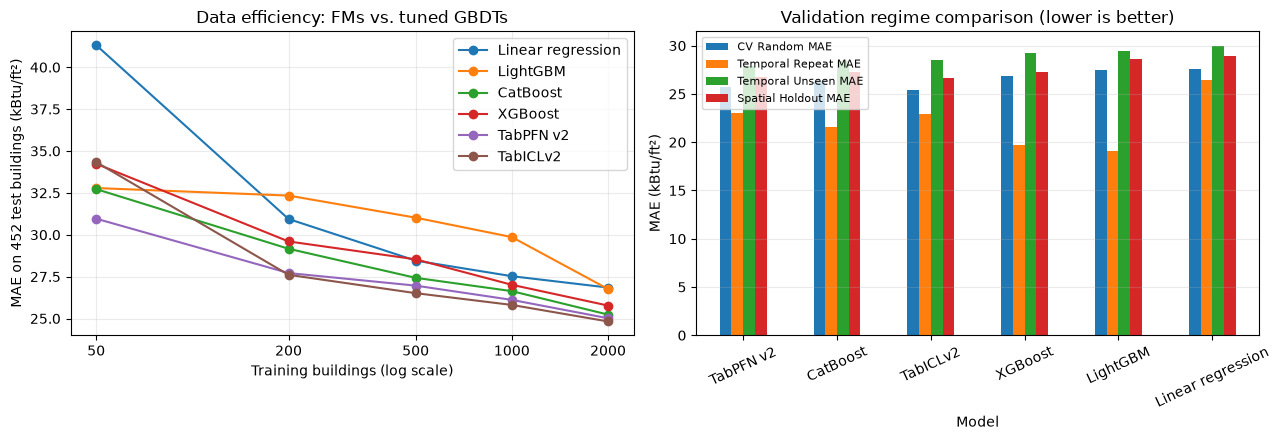

In [7]:
SIZES = [50, 200, 500, 1000, 2000]
REPEATS = 3
rng = np.random.default_rng(0)

curve_mae = {m: {n: [] for n in SIZES} for m in MODELS}
curve_sec = {m: {n: [] for n in SIZES} for m in MODELS}

with profiler.step("5. Scaling curve (5 sizes x 3 repeats x 6 models)", n_items=len(SIZES) * REPEATS * len(MODELS), item_unit="fit"):
    import time
    for rep in range(REPEATS):
        perm = rng.permutation(len(y22))
        test_idx = perm[:452]
        for n in SIZES:
            tr_idx = perm[452:452 + n]
            for name, make_model in MODELS.items():
                if DEVICE == "cuda":
                    torch.cuda.synchronize()
                t0 = time.perf_counter()
                m = make_model().fit(X22.values[tr_idx], y22[tr_idx])
                p = m.predict(X22.values[test_idx])
                if DEVICE == "cuda":
                    torch.cuda.synchronize()
                curve_sec[name][n].append(time.perf_counter() - t0)
                curve_mae[name][n].append(mae(y22[test_idx], p))
                del m
    free_gpu()

mae_tbl = pd.DataFrame({m: {n: np.mean(v) for n, v in curve_mae[m].items()} for m in MODELS})
sec_tbl = pd.DataFrame({m: {n: np.mean(v) for n, v in curve_sec[m].items()} for m in MODELS})
mae_tbl.index.name = "Training buildings"
display(mae_tbl.round(2))
profiler.record_metrics("Scaling_MAE_452test", mae_tbl.round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
mae_tbl.plot(ax=axes[0], marker="o", logx=True)
axes[0].set_xticks(SIZES, SIZES)
axes[0].minorticks_off()
axes[0].set_xlabel("Training buildings (log scale)")
axes[0].set_ylabel("MAE on 452 test buildings (kBtu/ft²)")
axes[0].set_title("Data efficiency: FMs vs. tuned GBDTs")
axes[0].grid(alpha=0.25)

plot_cols = ["CV Random MAE", "Temporal Repeat MAE", "Temporal Unseen MAE", "Spatial Holdout MAE"]
splits_df[plot_cols].plot.bar(ax=axes[1])
axes[1].set_ylabel("MAE (kBtu/ft²)")
axes[1].set_title("Validation regime comparison (lower is better)")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(IMG_DIR / "m2_benchmark_splits.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Operational, memory and energy summary

In [8]:
profiler.stop_run()
csv_path, json_path = profiler.save()
print(f"Saved step log to {csv_path.relative_to(ROOT)} and benchmark record to {json_path.relative_to(ROOT)}")

print("\n--- Model cards ---")
display(profiler.model_card_table())

print("\n--- Step-by-step operational profile ---")
display(profiler.summary_table())

print("\n--- Energy and CO2e summary (NVML GPU vs. CodeCarbon system) ---")
display(profiler.energy_summary_table())

Saved step log to data\cache\module2_tabular_runtime.csv and benchmark record to benchmarks\results\module2_tabular_02_tabular_fms_comparison.json

--- Model cards ---


,Params (M),Precision,Disk (MB),Peak VRAM (GB),Min Hardware,Licence,Limits
Model,,,,,,,
Linear regression,NaN,cpu/sklearn,NaN,0.011,CPU-ok,BSD-3-Clause,Linear only
LightGBM,NaN,cpu/sklearn,NaN,0.011,CPU-ok,MIT,Needs tuning for tiny n
CatBoost,NaN,cpu/sklearn,NaN,0.011,CPU-ok,Apache-2.0,Fast inference
XGBoost,NaN,cpu/sklearn,NaN,0.011,CPU-ok,Apache-2.0,Needs tuning for tiny n
TabPFN v2,11.08,float32,44.4,0.778,GPU <= 4 GB,Prior Labs (Apache 2.0 w/ attr.),"<= 10k rows, <= 500 cols"
TabICLv2,28.54,float32,114.3,2.708,GPU <= 4 GB,BSD-3-Clause,"Scales >100k rows, native quantiles"



--- Step-by-step operational profile ---


,Time (s),Peak VRAM (GB),Avg Power (W),GPU Energy (J),mJ / item,ms / item,CO2 CH (mg),CO2 EU (mg)
Step,,,,,,,,
1. Load Chicago 2021 & 2022 building data,0.2,0.00,43.7,8.0,NaN,NaN,0.07,0.51
2. 5-fold CV: Linear regression,0.1,0.00,26.2,1.8,0.73,0.03,0.01,0.11
2. 5-fold CV: LightGBM,30.3,0.00,25.7,781.0,318.52,12.37,6.51,49.90
2. 5-fold CV: CatBoost,10.7,0.00,25.2,270.5,110.31,4.36,2.25,17.28
2. 5-fold CV: XGBoost,18.4,0.00,25.2,462.3,188.53,7.49,3.85,29.54
2. 5-fold CV: TabPFN v2,10.4,0.36,137.7,1435.1,585.28,4.25,11.96,91.69
2. 5-fold CV: TabICLv2,9.2,1.44,111.9,1031.6,420.72,3.76,8.60,65.91
3. 5-fold Quantiles: LightGBM (quantile),62.0,0.01,27.7,1718.2,700.72,25.27,14.32,109.77
3. 5-fold Quantiles: TabPFN v2,9.6,0.36,148.8,1421.7,579.82,3.90,11.85,90.83



--- Energy and CO2e summary (NVML GPU vs. CodeCarbon system) ---


,Duration (s),GPU (Wh),"CPU + RAM (Wh, modeled)",Total (Wh),CO2 CH 30g/kWh (mg),CO2 EU 230g/kWh (mg),CO2 US 380g/kWh (mg)
Scope,,,,,,,
"Profiled steps (GPU only, NVML 50 ms)",430.9,6.2760,NaN,6.2760,188.28,1443.47,2384.87
Whole notebook (CodeCarbon offline: GPU + CPU/RAM model),445.6,5.5604,33.9061,39.4665,1184.00,9077.30,14997.28
